# 06 — Root finding and differentiable interpolation

**Objectives.** Solve parameterized implicit equations and embed lookup tables in differentiable graphs. For $g(z,p)=0$, the implicit sensitivity is $dz/dp=-(\partial g/\partial z)^{-1}(\partial g/\partial p)$ when the first Jacobian is nonsingular.


In [9]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

### Solve an implicit equation and differentiate the solution

The cell defines a residual `Function` and supplies it to
`ca.rootfinder` with the Newton plugin. The first rootfinder argument is an
initial guess and the second is the fixed parameter. Calling the rootfinder
with a symbolic parameter embeds the implicit solve in an MX graph, which
CasADi can differentiate through using the implicit-function theorem.

The root $z(p)$ satisfies

$$
g(z,p)=z^3+z-p=0.
$$

Newton's method applies

$$
z^{(i+1)}=z^{(i)}-
\frac{g(z^{(i)},p)}{\partial g/\partial z},
$$

while implicit differentiation gives

$$
\frac{dz}{dp}=-\frac{\partial g/\partial p}{\partial g/\partial z}
=\frac{1}{3z^2+1}.
$$

`dotdraw` visualizes the residual expression supplied to the solver.


root at p=2: 1 derivative dz/dp: 0.25


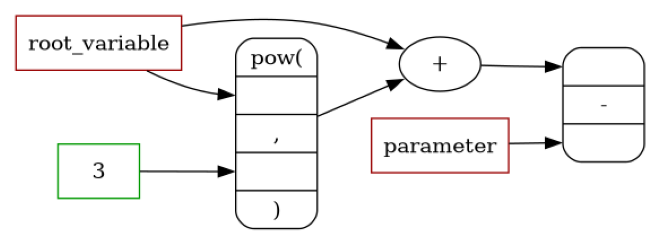

In [10]:
import casadi as ca
import numpy as np
from casadi.tools.graph import dotdraw

root_variable = ca.MX.sym("root_variable")
parameter = ca.MX.sym("parameter")
residual_expression = root_variable**3 + root_variable - parameter
residual_function = ca.Function(
    "root_residual",
    [root_variable, parameter],
    [residual_expression],
)

# rootfinder wraps a residual Function. The first call argument is the
# initial root guess; remaining arguments are the residual parameters.
root_solver = ca.rootfinder("root_solver", "newton", residual_function)
solution = root_solver(0.0, 2.0)
assert abs(float(solution**3 + solution - 2)) < 1e-10

# Calling the solver with a symbolic parameter keeps the implicit solution
# differentiable, so jacobian applies the implicit-function derivative.
symbolic_root = root_solver(0.0, parameter)
sensitivity_function = ca.Function(
    "root_sensitivity",
    [parameter],
    [ca.jacobian(symbolic_root, parameter)],
)
print(
    "root at p=2:",
    solution,
    "derivative dz/dp:",
    sensitivity_function(2.0),
)

dotdraw(residual_function(root_variable, parameter), direction="LR")

### Create differentiable lookup tables

`ca.interpolant` constructs callable lookup-table functions from a grid
and sampled values. The `linear` plugin uses piecewise-linear segments,
while `bspline` constructs a smooth B-spline representation. Because the
spline call remains symbolic, `ca.jacobian` can construct its slope as a
second CasADi function.

The tabulated function is sampled from

$$
y(q)=\sqrt{q+1},\qquad q\in[0,4].
$$

The lesson compares

$$
\widehat y_{\mathrm{linear}}(q),\qquad
\widehat y_{\mathrm{spline}}(q),\qquad
\frac{d\widehat y_{\mathrm{spline}}}{dq}.
$$

The final graph illustrates that even a table lookup can participate in a
differentiable CasADi expression graph.


linear: 1.4976761962286425 spline: 1.4999785097906928 spline slope: 0.3334121011593904


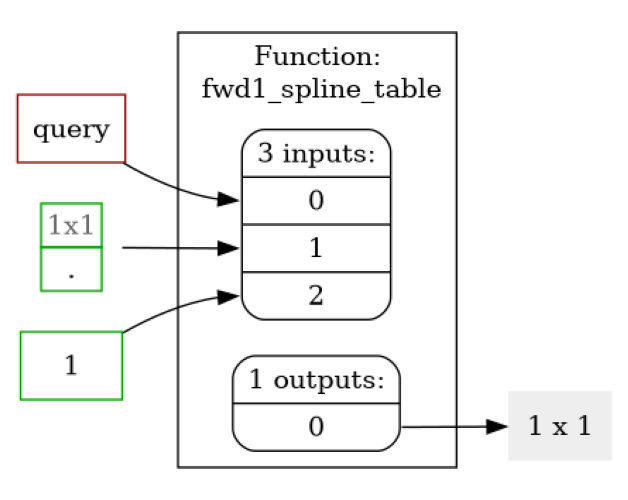

In [11]:
interpolation_grid = np.linspace(0, 4, 9)
table_values = np.sqrt(interpolation_grid + 1)

# interpolant creates a differentiable lookup-table Function. The plugin
# selects piecewise-linear or B-spline interpolation over the same data.
linear_interpolant = ca.interpolant(
    "linear_table",
    "linear",
    [interpolation_grid],
    table_values,
)
spline_interpolant = ca.interpolant(
    "spline_table",
    "bspline",
    [interpolation_grid],
    table_values,
)

query = ca.MX.sym("query")
spline_slope = ca.Function(
    "spline_slope",
    [query],
    [ca.jacobian(spline_interpolant(query), query)],
)
print(
    "linear:",
    float(linear_interpolant(1.25)),
    "spline:",
    float(spline_interpolant(1.25)),
    "spline slope:",
    float(spline_slope(1.25)),
)

dotdraw(spline_slope(query), direction="LR")

**Failure modes:** singular implicit Jacobians, poor initial guesses, extrapolation, and spline overshoot. `rootfinder.stats()` reports termination information. **Recap:** root finders and interpolants are Functions, so their outputs can participate in larger derivative graphs.
